In [ ]:
%pip install xgboost
%pip install xlrd

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 1.0/48.9 MB 3.8 MB/s eta 0:00:13
   -- ------------------------------------- 2.6/48.9 MB 5.2 MB/s eta 0:00:09
   --- ------------------------------------ 4.5/48.9 MB 6.5 MB/s eta 0:00:07
   ------ --------------------------------- 7.6/48.9 MB 8.5 MB/s eta 0:00:05
   -------- ------------------------------- 10.2/48.9 MB 9.3 MB/s eta 0:00:05
   --------- ------------------------------ 11.8/48.9 MB 9.1 MB/s eta 0:00:05
   ------------ --------------------------- 15.2/48.9 MB 10.1 MB/s eta 0:00:04
   -------------- ------------------------- 17.8/48.9 MB 10.5 MB/s eta 0:00:03
   ---------------- --------


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached xlrd-2.0.2-py2.py3-none-any.whl.metadata (3.5 kB)
Using cached xlrd-2.0.2-py2.py3-none-any.whl (96 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from pathlib import Path
import pandas as pd

data_path = (
    Path.home()
    / "Downloads"
    / "Orbital, Nasal and Craniofacial Class Pattern.xls"
)

df = pd.read_excel(data_path, sheet_name="Raw Data")

# Remove leading spaces and line breaks from column headings.
df.columns = df.columns.str.replace(r"\s+", " ", regex=True).str.strip()

print("Dataset shape:", df.shape)
print("Sex labels:")
print(df["Gender"].astype("string").str.strip().value_counts())

Dataset shape: (1042, 21)
Sex labels:
Gender
M    587
F    455
Name: count, dtype: int64[pyarrow]


In [ ]:
features = [
    "Ec-Dc Orbital Width",
    "REc-RDc Right Orbital Width",
    "LEc-LDc Left Orbital Width",
    "UMo-Lmo Orbital Height",
    "RUMo-RLMo Right Orbital Height",
    "LUMo-LLMo Left Orbital Height",
    "RAI-LAI Nasal Width",
    "Rh-Ns Nasal Height",
]

X = df[features].apply(pd.to_numeric, errors="raise")

# Explicit mapping: female = 0, male = 1.
labels = df["Gender"].astype("string").str.strip()
y = labels.map({"F": 0, "M": 1})

print("Input shape:", X.shape)
print("Missing measurement values:", X.isna().sum().sum())
print("Missing or unexpected labels:", y.isna().sum())

assert not X.isna().any().any(), "Check missing measurements."
assert not y.isna().any(), "Check missing or unexpected sex labels."

y = y.astype(int)

Input shape: (1042, 8)
Missing measurement values: 0
Missing or unexpected labels: 0


In [ ]:
import json
import hashlib
import platform
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import sklearn
import xgboost

from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

In [ ]:
current_folder = Path.cwd()

project_folder = (
    current_folder.parent
    if current_folder.name == "notebooks"
    else current_folder
)

output_folder = project_folder / "results" / "xgboost_baseline"
output_folder.mkdir(parents=True, exist_ok=True)

print("Results folder:", output_folder)

Results folder: c:\Users\jwenn\Desktop\UM\FYP\FYP-Project\results\xgboost_baseline


In [ ]:
train_indices, test_indices = train_test_split(
    np.arange(len(X)),
    test_size=0.2,
    random_state=42,
    stratify=y,
)

X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()

y_train = y.iloc[train_indices].copy()
y_test = y.iloc[test_indices].copy()

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

split_summary = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Testing": y_test.value_counts(),
}).rename(index={0: "Female", 1: "Male"})

display(split_summary)

Training: (833, 8)
Testing: (209, 8)


,Training,Testing
Gender,,
Male,469,118
Female,364,91


In [ ]:
training_patterns = set(
    X_train.itertuples(index=False, name=None)
)

overlap_count = sum(
    row in training_patterns
    for row in X_test.itertuples(index=False, name=None)
)

print(
    "Test records with measurements also present in training:",
    overlap_count
)

if overlap_count > 0:
    print(
        "Review these repeats before final evaluation. "
        "This run retains the original MLP split method."
    )

Test records with measurements also present in training: 1
Review these repeats before final evaluation. This run retains the original MLP split method.


In [ ]:
model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    subsample=1.0,
    colsample_bytree=1.0,
    tree_method="hist",
    random_state=42,
    n_jobs=1,
)

model.fit(X_train, y_train)

print("Training completed.")

Training completed.


In [ ]:
y_pred = model.predict(X_test)

male_class_column = list(model.classes_).index(1)
y_probability = model.predict_proba(X_test)[:, male_class_column]

print("Prediction completed.")

Prediction completed.


In [ ]:
metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision_male": float(
        precision_score(y_test, y_pred, zero_division=0)
    ),
    "recall_male": float(
        recall_score(y_test, y_pred, zero_division=0)
    ),
    "f1_male": float(
        f1_score(y_test, y_pred, zero_division=0)
    ),
    "f1_macro": float(
        f1_score(y_test, y_pred, average="macro", zero_division=0)
    ),
    "roc_auc": float(
        roc_auc_score(y_test, y_probability)
    ),
}

metrics_table = pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Score"]
)

display(
    metrics_table.style.format({"Score": "{:.2%}"})
)

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Female", "Male"],
        digits=4,
        zero_division=0,
    )
)

,Metric,Score
0,accuracy,70.33%
1,precision_male,73.33%
2,recall_male,74.58%
3,f1_male,73.95%
4,f1_macro,69.75%
5,roc_auc,78.30%


              precision    recall  f1-score   support

      Female     0.6629    0.6484    0.6556        91
        Male     0.7333    0.7458    0.7395       118

    accuracy                         0.7033       209
   macro avg     0.6981    0.6971    0.6975       209
weighted avg     0.7027    0.7033    0.7029       209



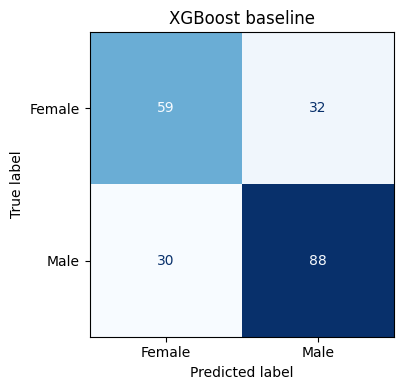

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1],
)

fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Female", "Male"],
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
)

ax.set_title("XGBoost baseline")
fig.tight_layout()

fig.savefig(
    output_folder / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

,Feature,Importance
7,Rh-Ns Nasal Height,0.381695
6,RAI-LAI Nasal Width,0.117229
0,Ec-Dc Orbital Width,0.109227
2,LEc-LDc Left Orbital Width,0.088426
3,UMo-Lmo Orbital Height,0.082634
4,RUMo-RLMo Right Orbital Height,0.077462
1,REc-RDc Right Orbital Width,0.076329
5,LUMo-LLMo Left Orbital Height,0.066997


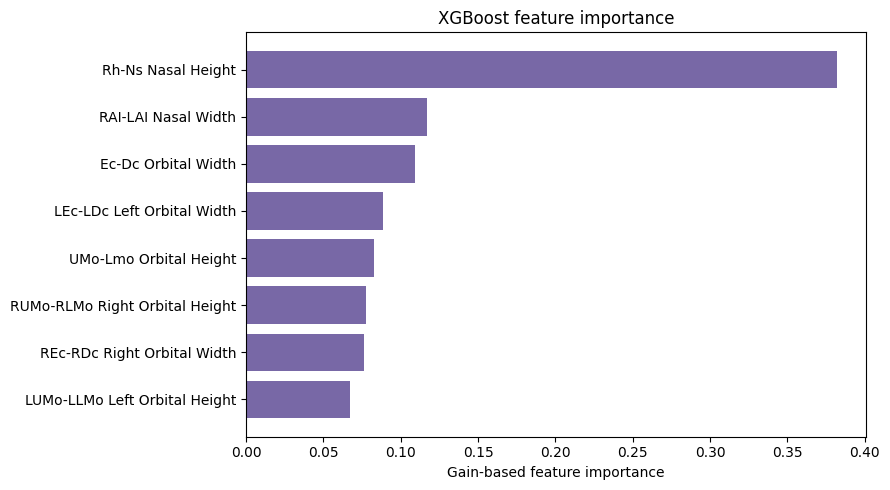

In [ ]:
importance_table = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_,
}).sort_values("Importance", ascending=False)

display(importance_table)

plot_data = importance_table.sort_values("Importance")

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    plot_data["Feature"],
    plot_data["Importance"],
    color="#7868A6",
)

ax.set_xlabel("Gain-based feature importance")
ax.set_title("XGBoost feature importance")

fig.tight_layout()

fig.savefig(
    output_folder / "feature_importance.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [ ]:
dataset_hash = hashlib.sha256(
    data_path.read_bytes()
).hexdigest()

model.save_model(
    str(output_folder / "xgboost_model.json")
)

metrics_table.to_csv(
    output_folder / "metrics.csv",
    index=False,
)

importance_table.to_csv(
    output_folder / "feature_importance.csv",
    index=False,
)

pd.DataFrame(
    cm,
    index=["Actual Female", "Actual Male"],
    columns=["Predicted Female", "Predicted Male"],
).to_csv(output_folder / "confusion_matrix.csv")

predictions = pd.DataFrame({
    "source_row_position": test_indices,
    "actual_label": y_test.to_numpy(),
    "predicted_label": y_pred,
    "probability_male": y_probability,
})

predictions.to_csv(
    output_folder / "test_predictions.csv",
    index=False,
)

split_details = {
    "dataset_sha256": dataset_hash,
    "sheet": "Raw Data",
    "features": features,
    "label_mapping": {"F": 0, "M": 1},
    "random_state": 42,
    "test_size": 0.2,
    "train_row_positions": train_indices.tolist(),
    "test_row_positions": test_indices.tolist(),
}

with open(output_folder / "split.json", "w", encoding="utf-8") as file:
    json.dump(split_details, file, indent=2)

run_details = {
    "model": "XGBoost initial baseline",
    "parameters": model.get_params(),
    "metrics": metrics,
    "matching_test_measurements_in_training": overlap_count,
    "python_version": platform.python_version(),
    "xgboost_version": xgboost.__version__,
    "sklearn_version": sklearn.__version__,
}

with open(
    output_folder / "run_details.json", "w", encoding="utf-8"
) as file:
    json.dump(run_details, file, indent=2)

print("Saved model and results to:", output_folder)

Saved model and results to: c:\Users\jwenn\Desktop\UM\FYP\FYP-Project\results\xgboost_baseline


In [ ]:
loaded_model = XGBClassifier()

loaded_model.load_model(
    str(output_folder / "xgboost_model.json")
)

loaded_predictions = loaded_model.predict(X_test)

assert np.array_equal(y_pred, loaded_predictions)

print("Saved model loaded successfully; predictions match.")

Saved model loaded successfully; predictions match.


: 